In [ ]:
print("Họ tên: Đàm Hoàng Lam - MSSV: 6451071039")

# Linear algebra
import numpy as np

# data processing
import pandas as pd

# data visualization
import seaborn as sns
%matplotlib inline
from matplotlib import pyplot as plt
from matplotlib import style

# Đọc dữ liệu đầu vào (file bank.csv ngăn cách bằng dấu chấm phẩy ';')
with open('bank.csv', encoding='utf-8') as f:
    df = pd.read_csv(f, sep=';')

# Xem xét dữ liệu ban đầu với hàm head(), info(), describe()
display(df.head(12))
df.info()
display(df.describe())

Họ tên: Đàm Hoàng Lam - MSSV: 6451071039


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,30,unemployed,married,primary,no,1787,no,no,cellular,19,oct,79,1,-1,0,unknown,no
1,33,services,married,secondary,no,4789,yes,yes,cellular,11,may,220,1,339,4,failure,no
2,35,management,single,tertiary,no,1350,yes,no,cellular,16,apr,185,1,330,1,failure,no
3,30,management,married,tertiary,no,1476,yes,yes,unknown,3,jun,199,4,-1,0,unknown,no
4,59,blue-collar,married,secondary,no,0,yes,no,unknown,5,may,226,1,-1,0,unknown,no
5,35,management,single,tertiary,no,747,no,no,cellular,23,feb,141,2,176,3,failure,no
6,36,self-employed,married,tertiary,no,307,yes,no,cellular,14,may,341,1,330,2,other,no
7,39,technician,married,secondary,no,147,yes,no,cellular,6,may,151,2,-1,0,unknown,no
8,41,entrepreneur,married,tertiary,no,221,yes,no,unknown,14,may,57,2,-1,0,unknown,no
9,43,services,married,primary,no,-88,yes,yes,cellular,17,apr,313,1,147,2,failure,no


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4521 entries, 0 to 4520
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        4521 non-null   int64 
 1   job        4521 non-null   object
 2   marital    4521 non-null   object
 3   education  4521 non-null   object
 4   default    4521 non-null   object
 5   balance    4521 non-null   int64 
 6   housing    4521 non-null   object
 7   loan       4521 non-null   object
 8   contact    4521 non-null   object
 9   day        4521 non-null   int64 
 10  month      4521 non-null   object
 11  duration   4521 non-null   int64 
 12  campaign   4521 non-null   int64 
 13  pdays      4521 non-null   int64 
 14  previous   4521 non-null   int64 
 15  poutcome   4521 non-null   object
 16  y          4521 non-null   object
dtypes: int64(7), object(10)
memory usage: 600.6+ KB


,age,balance,day,duration,campaign,pdays,previous
count,4521.000000,4521.000000,4521.000000,4521.000000,4521.000000,4521.000000,4521.000000
mean,41.170095,1422.657819,15.915284,263.961292,2.793630,39.766645,0.542579
std,10.576211,3009.638142,8.247667,259.856633,3.109807,100.121124,1.693562
min,19.000000,-3313.000000,1.000000,4.000000,1.000000,-1.000000,0.000000
25%,33.000000,69.000000,9.000000,104.000000,1.000000,-1.000000,0.000000
50%,39.000000,444.000000,16.000000,185.000000,2.000000,-1.000000,0.000000
75%,49.000000,1480.000000,21.000000,329.000000,3.000000,-1.000000,0.000000
max,87.000000,71188.000000,31.000000,3025.000000,50.000000,871.000000,25.000000


câu 2

In [ ]:
print("Họ tên: Đàm Hoàng Lam - MSSV: 6451071039")

import numpy as np
import pandas as pd

with open('bank.csv', encoding='utf-8') as f:
  df = pd.read_csv(f, sep=';')

# Chuyển các giá trị 'unknown' thành NaN (giá trị rỗng)
df.replace('unknown', np.nan, inplace=True)

# Thống kê số lượng và tỷ lệ % giá trị rỗng nhiều nhất (giống hệt code mẫu của thầy)
total = df.isnull().sum().sort_values(ascending=False)
percent_1 = df.isnull().sum() / df.isnull().count() * 100
percent_2 = (round(percent_1, 1)).sort_values(ascending=False)
missing_data = pd.concat([total, percent_2], axis=1, keys=['Total', '%'])
display(missing_data.head(5))

Họ tên: Đàm Hoàng Lam - MSSV: 6451071039


,Total,%
poutcome,3705,82.0
contact,1324,29.3
education,187,4.1
job,38,0.8
age,0,0.0


Câu 3: Vẽ biểu đồ khảo sát sự liên quan giữa Độ tuổi (age), Tình trạng hôn nhân (marital) và Thuộc tính quyết định (y)

Họ tên: Đàm Hoàng Lam - MSSV: 6451071039


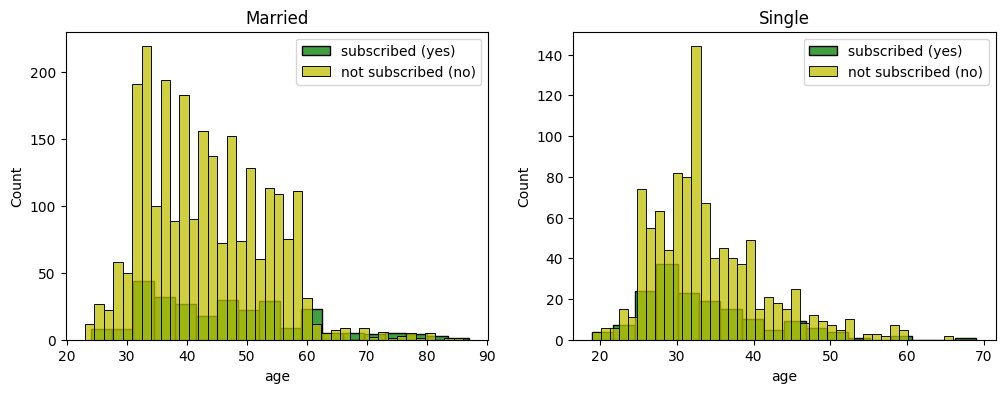

In [ ]:
print("Họ tên: Đàm Hoàng Lam - MSSV: 6451071039")

import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib import pyplot as plt

with open('bank.csv', encoding='utf-8') as f:
  df = pd.read_csv(f, sep=';')

# Biến đổi cột quyết định 'y' sang 0 và 1 để khảo sát giống cột 'survived'
df['subscribe'] = df['y'].map({'no': 0, 'yes': 1})

subscribed = 'subscribed (yes)'
not_subscribed = 'not subscribed (no)'
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(12, 4))

married = df[df['marital'] == 'married']
single = df[df['marital'] == 'single']

# Biểu đồ 1: Nhóm đã kết hôn (Married)
ax = sns.histplot(
    married[married['subscribe'] == 1].age.dropna(),
    bins=18,
    label=subscribed,
    ax=axes[0],
    kde=False,
    color='g',
)
ax = sns.histplot(
    married[married['subscribe'] == 0].age.dropna(),
    bins=40,
    label=not_subscribed,
    ax=axes[0],
    kde=False,
    color='y',
)
ax.legend()
ax.set_title('Married')

# Biểu đồ 2: Nhóm độc thân (Single)
ax = sns.histplot(
    single[single['subscribe'] == 1].age.dropna(),
    bins=18,
    label=subscribed,
    ax=axes[1],
    kde=False,
    color='g',
)
ax = sns.histplot(
    single[single['subscribe'] == 0].age.dropna(),
    bins=40,
    label=not_subscribed,
    ax=axes[1],
    kde=False,
    color='y',
)
ax.legend()
ax.set_title('Single')
plt.show()

Câu 4: Vẽ biểu đồ khảo sát Trình độ học vấn (education), Khoản vay nhà (housing) với Khả năng đăng ký (subscribe)

Họ tên: Đàm Hoàng Lam - MSSV: 6451071039


/usr/local/lib/python3.13/dist-packages/seaborn/axisgrid.py:854: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:#1f77b4'` for the same effect.

  func(*plot_args, **plot_kwargs)
/usr/local/lib/python3.13/dist-packages/seaborn/axisgrid.py:854: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:#1f77b4'` for the same effect.

  func(*plot_args, **plot_kwargs)


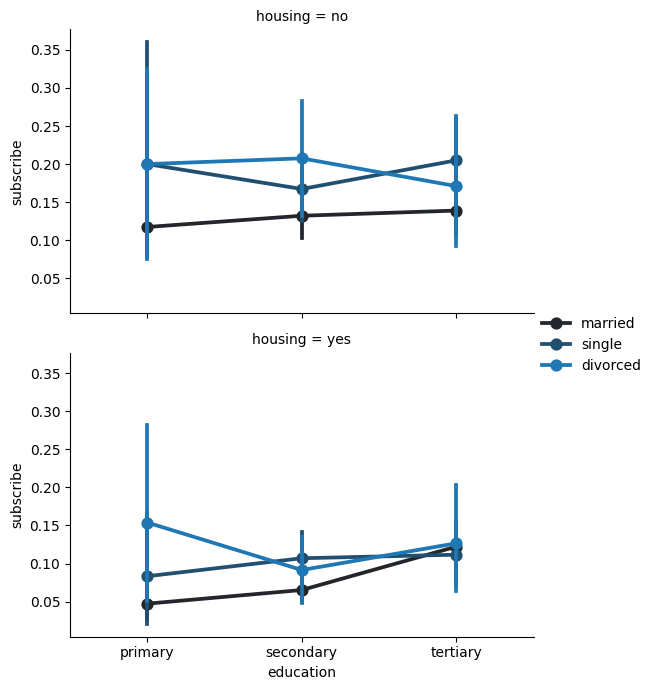

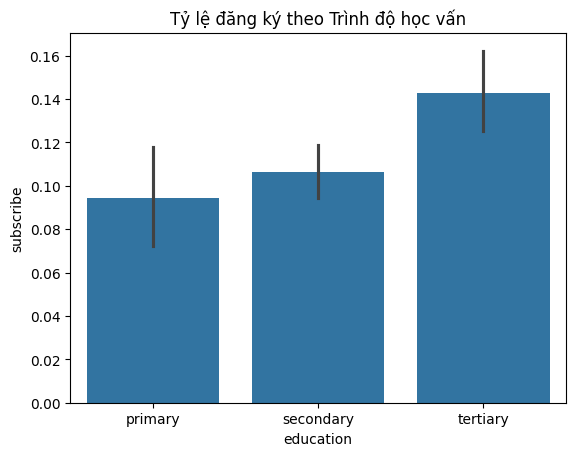

In [ ]:
print("Họ tên: Đàm Hoàng Lam - MSSV: 6451071039")

import pandas as pd
import seaborn as sns
from matplotlib import pyplot as plt

with open('bank.csv', encoding='utf-8') as f:
  df = pd.read_csv(f, sep=';')

df['subscribe'] = df['y'].map({'no': 0, 'yes': 1})

# Biểu đồ FacetGrid khảo sát housing, education, marital với subscribe
FacetGrid = sns.FacetGrid(df, row='housing', height=3.5, aspect=1.6)
FacetGrid.map(
    sns.pointplot,
    'education',
    'subscribe',
    'marital',
    palette=None,
    order=['primary', 'secondary', 'tertiary'],
    hue_order=['married', 'single', 'divorced'],
)
FacetGrid.add_legend()
plt.show()

# Biểu đồ barplot khảo sát tỷ lệ đăng ký theo Trình độ học vấn (education)
sns.barplot(
    x='education',
    y='subscribe',
    data=df,
    order=['primary', 'secondary', 'tertiary'],
)
plt.title('Tỷ lệ đăng ký theo Trình độ học vấn')
plt.show()

Câu 5: Tiền xử lý các thuộc tính thiếu dữ liệu và xóa bỏ các thuộc tính không cần thiết

In [ ]:
print("Họ tên: Đàm Hoàng Lam - MSSV: 6451071039")

import numpy as np
import pandas as pd

with open('bank.csv', encoding='utf-8') as f:
  df = pd.read_csv(f, sep=';')

df.replace('unknown', np.nan, inplace=True)

# 1. Xóa các thuộc tính thiếu quá nhiều dữ liệu (poutcome 82%, contact 29%) và các cột thời gian phụ
df = df.drop(['poutcome', 'contact', 'day', 'month', 'pdays', 'previous'], axis=1)

# 2. Điền giá trị thiếu (NaN) cho 'job' và 'education' bằng giá trị phổ biến nhất (mode)
for col in ['job', 'education']:
  common_value = df[col].mode()[0]
  df[col] = df[col].fillna(common_value)

# Kiểm tra lại xem còn giá trị rỗng không
print(df.isnull().sum())
display(df.head(5))

Họ tên: Đàm Hoàng Lam - MSSV: 6451071039
age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
duration     0
campaign     0
y            0
dtype: int64


,age,job,marital,education,default,balance,housing,loan,duration,campaign,y
0,30,unemployed,married,primary,no,1787,no,no,79,1,no
1,33,services,married,secondary,no,4789,yes,yes,220,1,no
2,35,management,single,tertiary,no,1350,yes,no,185,1,no
3,30,management,married,tertiary,no,1476,yes,yes,199,4,no
4,59,blue-collar,married,secondary,no,0,yes,no,226,1,no


Câu 6: Biến đổi các thuộc tính về dạng số, rời rạc hóa và tạo thuộc tính mới

In [ ]:
print("Họ tên: Đàm Hoàng Lam - MSSV: 6451071039")

import numpy as np
import pandas as pd

with open('bank.csv', encoding='utf-8') as f:
  df = pd.read_csv(f, sep=';')

df.replace('unknown', np.nan, inplace=True)
df = df.drop(['poutcome', 'contact', 'day', 'month', 'pdays', 'previous'], axis=1)
df['job'] = df['job'].fillna(df['job'].mode()[0])
df['education'] = df['education'].fillna(df['education'].mode()[0])

# 1. Chuyển đổi các thuộc tính nhị phân ('no': 0, 'yes': 1)
binary_map = {'no': 0, 'yes': 1}
for col in ['default', 'housing', 'loan', 'y']:
  df[col] = df[col].map(binary_map)
df.rename(columns={'y': 'subscribe'}, inplace=True)

# 2. Chuyển đổi thuộc tính 'marital', 'education', 'job' thành số
marital_map = {'married': 0, 'single': 1, 'divorced': 2}
df['marital'] = df['marital'].map(marital_map)

edu_map = {'primary': 1, 'secondary': 2, 'tertiary': 3}
df['education'] = df['education'].map(edu_map)

jobs = {name: idx for idx, name in enumerate(df['job'].unique())}
df['job'] = df['job'].map(jobs)

# 3. Chia giá trị thuộc tính tuổi (age) thành các nhóm (rời rạc hóa giống thầy)
df.loc[df['age'] <= 25, 'age'] = 0
df.loc[(df['age'] > 25) & (df['age'] <= 32), 'age'] = 1
df.loc[(df['age'] > 32) & (df['age'] <= 40), 'age'] = 2
df.loc[(df['age'] > 40) & (df['age'] <= 50), 'age'] = 3
df.loc[(df['age'] > 50) & (df['age'] <= 60), 'age'] = 4
df.loc[df['age'] > 60, 'age'] = 5

# 4. Chia thuộc tính thời lượng cuộc gọi (duration) thành 4 nhóm cân bằng bằng qcut
df['duration_group'] = pd.qcut(df['duration'], q=4, labels=[0, 1, 2, 3]).astype(
    int
)

# 5. Tạo thuộc tính mới: Số dư trung bình trên mỗi lần liên hệ (balance_per_campaign)
df['balance_per_campaign'] = (df['balance'] / df['campaign']).astype(int)

# Xem kết quả bảng dữ liệu sạch cuối cùng
display(df.head(10))

Họ tên: Đàm Hoàng Lam - MSSV: 6451071039


,age,job,marital,education,default,balance,housing,loan,duration,campaign,subscribe,duration_group,balance_per_campaign
0,1,0,0,1,0,1787,0,0,79,1,0,0,1787
1,2,1,0,2,0,4789,1,1,220,1,0,2,4789
2,2,2,1,3,0,1350,1,0,185,1,0,1,1350
3,1,2,0,3,0,1476,1,1,199,4,0,2,369
4,4,3,0,2,0,0,1,0,226,1,0,2,0
5,2,2,1,3,0,747,0,0,141,2,0,1,373
6,2,4,0,3,0,307,1,0,341,1,0,3,307
7,2,5,0,2,0,147,1,0,151,2,0,1,73
8,3,6,0,3,0,221,1,0,57,2,0,0,110
9,3,1,0,1,0,-88,1,1,313,1,0,2,-88
